# Correlations

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal

## Loading Data

In [2]:
def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df.set_index(pd.to_datetime(df["Unnamed: 0"]), inplace=True)
        df.drop("Unnamed: 0", inplace=True, axis="columns")
    # Convert back to complex numbers
    # https://stackoverflow.com/questions/18919699/python-pandas-complex-number
    # for i,col in enumerate(df.columns):
    #     # basically, if column is complex
    #     if not is_numeric_dtype(df[col]):
    #         df[col] = df[col].apply(lambda x: complex(x))
    df = df.fillna(0)
    return df


def read_csv(path):
    csv = pd.read_csv(path)
    return clean_csv(csv)


def smooth(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(
        window
    )  # smooth by convolving speed with window
    return smoothed

In [3]:
surface_stress = pd.read_csv("../../derived_data/daily_momentum_transfer.csv")
surface_stress.set_index(pd.to_datetime(surface_stress["Unnamed: 0"]), inplace=True)
surface_stress.drop("Unnamed: 0", inplace=True, axis="columns")
for i, col in enumerate(surface_stress.columns):
    surface_stress[col] = surface_stress[col].str.replace("i", "j").apply(lambda x: complex(x))
surface_stress = surface_stress.abs()
surface_stress_at_C = pd.Series(
    index=surface_stress["C"].index, data=smooth(surface_stress["C"], 8)
)
_surface_stress_at_C = pd.Series(index=surface_stress["C"].index, data=surface_stress["C"])
print(surface_stress_at_C.iloc[8:-76])

Unnamed: 0
2017-02-12    0.027036
2017-02-17    0.024650
2017-02-22    0.033616
2017-02-27    0.054257
2017-03-04    0.075663
                ...   
2018-11-24    0.054600
2018-11-29    0.068301
2018-12-04    0.075549
2018-12-09    0.070095
2018-12-14    0.052702
Length: 135, dtype: float64


In [4]:
velocity = pd.read_csv("../../derived_data/velo_at_C.csv")
velocity.set_index(pd.to_datetime(velocity["time_2350"]), inplace=True)
velocity.drop("time_2350", inplace=True, axis="columns")
velocity["2350"] = velocity["2350"].apply(lambda x: complex(x))
# 5 day resampled, absolute value and time shifted, as resample used the left bin edge for labeling
mean_flow = (
    pd.Series(index=velocity.index + pd.Timedelta(hours=48), data=velocity["2350"].values)
    .resample("5D")
    .mean()
    .abs()
)
mean_flow

time_2350
2017-01-28    0.072623
2017-02-02    0.098450
2017-02-07    0.047789
2017-02-12    0.024011
2017-02-17    0.070628
                ...   
2019-01-08    0.038873
2019-01-13    0.077872
2019-01-18    0.079738
2019-01-23    0.045898
2019-01-28    0.008899
Freq: 5D, Length: 147, dtype: float64

In [43]:
np.shape(velocity.squeeze(axis=0).values.flatten())

(8796,)

In [42]:
def filter_to_2_to_30_days(series: pd.Series) -> pd.Series:
    fs = 1 / (2 * 60 * 60)  # sampling period of 2 hours
    lowcut = 1 / (30 * 60 * 60 * 24)  # period of 30 days
    highcut = 1 / (2 * 60 * 60 * 24)  # period of 2 days
    order = 40

    sos = signal.butter(order, [lowcut, highcut], "bandpass", fs=fs, output="sos")
    # use filtfilt with 2 filtering passes to prevent an artificial phase shift
    slow_oscillations = pd.Series(
        index=series, data=signal.sosfiltfilt(sos, series.values.flatten())
    )
    return slow_oscillations


velocity_2_30_days = filter_to_2_to_30_days(velocity.squeeze(axis=0))
plt.plot(velocity.index, velocity.values)

ValueError: Index data must be 1-dimensional

In [5]:
nsquared = read_csv("../../derived_data/N2_at_C_2350m.csv")
nsquared = (
    pd.Series(index=nsquared.index + pd.Timedelta(hours=48), data=nsquared.values.flatten())
    .resample("5D")
    .mean()
)
nsquared
# truncated_nsquared = nsquared.resample("5D", origin=smoothed_hke.index[0]).mean().loc[smoothed_hke.index[0]:smoothed_hke.index[-1]]
# truncated_nsquared.plot(ax=ax)
# truncated_nsquared

Unnamed: 0
2017-01-28    0.000002
2017-02-02    0.000002
2017-02-07    0.000002
2017-02-12    0.000002
2017-02-17    0.000002
                ...   
2019-01-08    0.000002
2019-01-13    0.000002
2019-01-18    0.000002
2019-01-23    0.000002
2019-01-28    0.000002
Freq: 5D, Length: 147, dtype: float64

In [6]:
hke = pd.read_csv("../../derived_data/HKE.csv", index_col=0, header=[0, 1])
hke.index = pd.to_datetime(hke.index).floor("d")
# results.index = multi_index
hke = hke["C", "2350"]

In [7]:
dissip_IGW_at_C = pd.read_csv(
    "../../derived_data/wave_induced_dissipation_rate_time_series_at_C.csv"
)
dissip_IGW_at_C.set_index(pd.to_datetime(dissip_IGW_at_C["Unnamed: 0"]), inplace=True)
dissip_IGW_at_C.drop("Unnamed: 0", inplace=True, axis="columns")
dissip_IGW_at_C

,0
Unnamed: 0,
2017-02-12,8.252667e-10
2017-02-17,8.708783e-10
2017-02-22,8.313334e-10
2017-02-27,9.406800e-10
2017-03-04,1.544095e-09
...,...
2018-12-24,9.840217e-10
2018-12-29,1.178971e-09
2019-01-03,1.208642e-09


## Computation functions

In [8]:
def cross_corr(x, y):
    "Plot cross-correlation (same) between two signals."
    N = max(len(x), len(y))
    n = min(len(x), len(y))

    lags = signal.correlation_lags(len(x), len(y), mode="same")
    # c = signal.correlate(x / np.std(x), y / np.std(y), 'same')
    # print(np.nanmean(x), np.nanmean(y), np.nanstd(x) ,np.nanstd(y))
    c = signal.correlate(x - np.nanmean(x), y - np.nanmean(y), "same") / (
        np.nanstd(x) * np.nanstd(y)
    )

    # ax.plot(lags, c / n)
    return lags, c / n

## Plotting functions

In [9]:
import matplotlib as mpl
from matplotlib.collections import PolyCollection


def plot_xy_errorbands(
    x,
    y,
    x_errors,
    y_errors,
    x_style: dict = {},
    y_style: dict = {},
    x_label: str = "",
    y_label: str = "",
    plot_errorbars: bool = False,
    ax: mpl.axes.Axes = None,
):

    x_lower = x - x_errors
    x_upper = x + x_errors
    y_lower = y - y_errors
    y_upper = y + y_errors

    if ax is None:
        fig, ax = plt.subplots(1)

    if plot_errorbars:
        ax.errorbar(
            x,
            y,
            xerr=x_errors,
            yerr=y_errors,
            fmt="o",
            linestyle="None",
            color="blue",
            label="points",
        )

    # Build a list of quads between consecutive points
    verts = [
        [
            (x_upper[i], y[i]),
            (x_upper[i + 1], y[i + 1]),
            (x_lower[i + 1], y[i + 1]),
            (x_lower[i], y[i]),
        ]
        for i in range(len(x) - 1)
    ]

    poly = PolyCollection(
        verts, **x_style
    )  # facecolors=["seagreen"], alpha=0.3, edgecolors="none")
    ax.add_collection(poly)

    ax.fill_between(x, y_lower, y_upper, **y_style, label=y_label)

In [10]:
def get_pearson_standard_error(x, y, N):
    # standard error of pearson correlation according to Bonett2008, recommended in Gnambs2023
    standard_error = (1 - y**2) / np.sqrt(N - 3)
    return standard_error
    # axis.fill_between(x,y-standard_error,y+standard_error, color=color, alpha=alpha, edgecolor=None)


def plot_corr_with_xy_error_bands(x, y, N, axis, label, color, plot_errorbars=False):
    y_style = {"hatch": "||||", "facecolor": "None", "linewidth": 0}
    x_style = {"hatch": "---", "facecolor": "None", "linewidth": 0}
    x_style["edgecolor"] = color
    y_style["edgecolor"] = color
    # x=5*lags_tau_HKE
    # y=corr_tau_HKE
    x_err = 10
    y_err = get_pearson_standard_error(x=x, y=y, N=N)
    plot_xy_errorbands(x, y, x_err, y_err, x_style, y_style, plot_errorbars=plot_errorbars, ax=axis)
    axis.plot(x, y, color=color, label=label, lw=2.5)

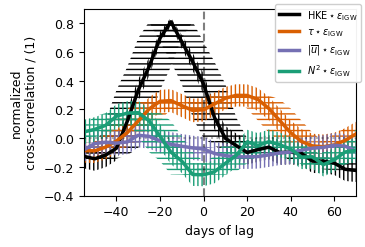

In [14]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

fig, ax = plt.subplots(ncols=1, figsize=(9 * cm, 6 * cm), layout="constrained")
ax = ["", ax]
ax[1].axhline(0, color="k", alpha=0.3, ls=":")
ax[1].axvline(0, color="k", alpha=0.5, ls="--")

# ax[1].xaxis.set_major_locator(mticker.FixedLocator(np.arange(-100, 150, 50)))
# ax[1].xaxis.set_minor_locator(mticker.FixedLocator(np.arange(-100, 110, 25)))

a = hke.iloc[3:]
b = dissip_IGW_at_C.iloc[:-3]
assert np.all(a.index == b.index)
lags, cross = cross_corr(a.values.flatten(), b.values.flatten())
x = lags * dissip_IGW_at_C.index.diff().mean().days
y = cross
N = len(dissip_IGW_at_C)
label = "$\\text{HKE} \\star \\varepsilon_\\mathrm{IGW}$"
color = "k"
plot_corr_with_xy_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

# a = surface_stress["C"].abs().iloc[8:-73]
a = surface_stress_at_C.iloc[8:-76]
b = dissip_IGW_at_C.iloc[:-6]
assert np.all(a.index == b.index)
lags, cross = cross_corr(a.values, b.values.flatten())
x = lags * dissip_IGW_at_C.index.diff().mean().days
y = cross
N = len(dissip_IGW_at_C)
label = "$\\tau \\star \\varepsilon_\\mathrm{IGW}$"
color = "#d95f02"
plot_corr_with_xy_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

a = mean_flow.iloc[3:-3]
b = dissip_IGW_at_C.iloc[:]
assert np.all(a.index == b.index)
lags, cross = cross_corr(smooth(a.values.flatten(), 8), b.values.flatten())
x = lags * dissip_IGW_at_C.index.diff().mean().days
y = cross
N = len(dissip_IGW_at_C)
label = "$|\\overline{u}| \\star \\varepsilon_\\mathrm{IGW}$"
color = "#7570b3"
plot_corr_with_xy_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

a = nsquared.iloc[3:-3]
b = dissip_IGW_at_C.iloc[:]
assert np.all(a.index == b.index)
lags, cross = cross_corr(a.values, b.values.flatten())
x = lags * dissip_IGW_at_C.index.diff().mean().days
y = cross
N = len(dissip_IGW_at_C)
label = "$N^2 \\star \\varepsilon_\\mathrm{IGW}$"
color = "#1b9e77"
plot_corr_with_xy_error_bands(x, y, N, axis=ax[1], label=label, color=color, plot_errorbars=False)

# a = surface_stress_at_C.iloc[8:-76]
# b = hke.iloc[3:-3]
# # a = surface_stress_at_C.iloc[8:-73]
# # b = hke.iloc[3:]
# assert np.all(a.index==b.index )
# lags, cross = cross_corr(a.values, b.values.flatten())
# x= lags * dissip_IGW_at_C.index.diff().mean().days
# y= cross
# N=len(surface_stress_at_C)
# label="$\\tau \\star \\text{HKE}$"
# color="tab:red"
# plot_corr_with_xy_error_bands(x,y,N,axis=ax[1],label=label,color=color,plot_errorbars=False)

# a = _surface_stress_at_C.iloc[8:-73]
# b = hke.iloc[3:]
# assert np.all(a.index==b.index )
# lags, cross = cross_corr(a.values, b.values.flatten())
# x= lags * dissip_IGW_at_C.index.diff().mean().days
# y= cross
# N=len(surface_stress_at_C)
# label="$2. \\tau \\star \\text{HKE}$"
# color="tab:blue"
# plot_corr_with_xy_error_bands(x,y,N,axis=ax[1],label=label,color=color,plot_errorbars=False)

ax[1].set_xlim(-55, 70)
ax[1].set_xlabel("days of lag")
ax[1].set_ylabel("normalized\ncross-correlation / (1)")
# #ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.legend(fontsize=7, loc="upper right", framealpha=0.95)  # , ncols=2)
fig.savefig("surface_dissip_corr.pdf")

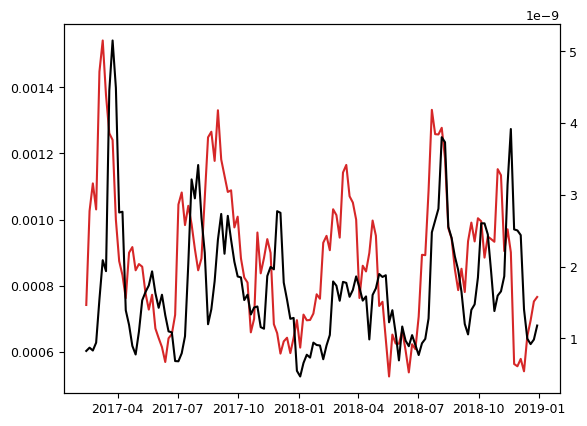

In [12]:
a = hke.iloc[3:]
b = dissip_IGW_at_C.iloc[:-3]
plt.plot(a.index, a, "tab:red")
ax2 = plt.gca().twinx()
# ax2.plot(dissip_IGW_at_C.index,dissip_IGW_at_C,"k")
ax2.plot(b.index, b, "k")
# c = smooth(nsquared.values.flatten(),8)
# ax2.plot(nsquared.index[3:],(c-np.mean(c))[3:],"k")

In [13]:
lags, cross = cross_corr(a.values, b.values)
plt.plot(lags, cross)
cross

ValueError: in1 and in2 should have the same dimensionality

In [ ]:
plt.axhline(0, color="lightgrey")
plt.axvline(0, color="lightgrey")
plt.plot(np.arange(-2, 5), np.arange(-2, 5), ls=":", color="k", alpha=0.6)

x = dissip_IGW_at_C.values.flatten()[:-33]
y = surface_stress["C"].abs().iloc[8:-103].values
plt.plot((x - np.nanmean(x)) / np.nanstd(x), (y - np.nanmean(y)) / np.nanstd(y), ".")

# , y-np.nanmean(y), 'same') / (np.nanstd(x) * np.nanstd(y))

In [ ]:
np.corrcoef(dissip_IGW_at_C.values.flatten()[:-33], surface_stress["C"].abs().iloc[8:-103].values)